# Player-viewpoint role classification

**Analytical question:** Encode relative geometry and classify roles.

**Stages in this notebook:** Relative bearings; sector membership; teammate/opponent counts; softmax training.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## Manufacture angular count features
For a given player, compute relative angles to every other player. Sweep 24 headings and count objects inside a 90° sector. Rotate both axes for attack-left teams. Pleuler's original method counts teammates; the opponent channel is our extension. This models relative geometry, not gaze or occluded vision.

#### Helper: `angular_counts`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [4]:
def angular_counts(nodes,pid,attack_sign=1,bins=24,fov=90):
    p=nodes[nodes.player_id.eq(pid)].iloc[0]
    others=nodes[~nodes.player_id.eq(pid)]
    delta=attack_sign*(others[['x','y']].to_numpy()-p[['x','y']].to_numpy(dtype=float))
    angles=np.arctan2(delta[:,1],delta[:,0]);headings=np.linspace(-np.pi,np.pi,bins,endpoint=False)
    difference=np.angle(np.exp(1j*(angles[:,None]-headings)))
    inside=np.abs(difference)<=np.deg2rad(fov/2)+1e-12
    same=others.team_id.eq(p.team_id).to_numpy()
    return headings,inside[same].sum(axis=0),inside[~same].sum(axis=0)

,player_id,metadata_role,mate_0,mate_1,mate_2,mate_3,mate_4,mate_5,mate_6,mate_7
0,11897,RB,1,1,0,0,0,0,0,0
1,287934,RDM,2,2,2,1,1,2,1,2
2,50982,LB,0,1,1,3,4,5,8,8
3,50999,GK,0,0,0,0,0,0,0,1
4,51002,LDM,5,4,4,2,3,3,3,3


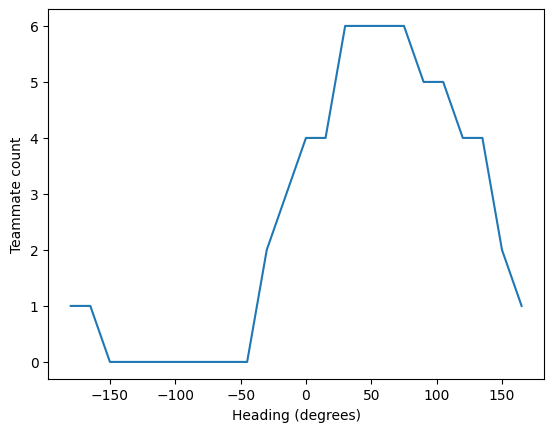

In [5]:
rows=[]
for _,p in snapshot.iterrows():
    angles,mates,opponents=angular_counts(snapshot,p.player_id,attack_sign=-1 if p.team_id==1802 else 1)
    rows.append(dict(player_id=p.player_id,metadata_role=role_labels[p.player_id],**{f'mate_{i}':v for i,v in enumerate(mates)},**{f'opp_{i}':v for i,v in enumerate(opponents)}))
features=pd.DataFrame(rows)
display(features.iloc[:5,:10])
plt.plot(np.degrees(angles),features.filter(like='mate_').iloc[0].to_numpy())
plt.xlabel('Heading (degrees)')
plt.ylabel('Teammate count')
plt.show()

### Intermediate steps: Angles, sector membership and binned counts

Summing the membership matrix across teammate rows produces the angular feature waveform. Opponent counts sum the other rows.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `relative_bearings`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [6]:
def relative_bearings(nodes,pid,sign):
    player=nodes[nodes.player_id.eq(pid)].iloc[0]
    others=nodes[~nodes.player_id.eq(pid)].copy()
    delta=sign*(others[['x','y']].to_numpy()-player[['x','y']].to_numpy(dtype=float))
    others['bearing']=np.arctan2(delta[:,1],delta[:,0]);others['same_team']=others.team_id.eq(player.team_id)
    return others

,player_id,same_team,bearing
67704,11897,False,0.448022
86163,50982,False,-0.531626
110775,50999,True,3.008134
36939,51002,True,0.332122
129234,51043,True,-1.135911


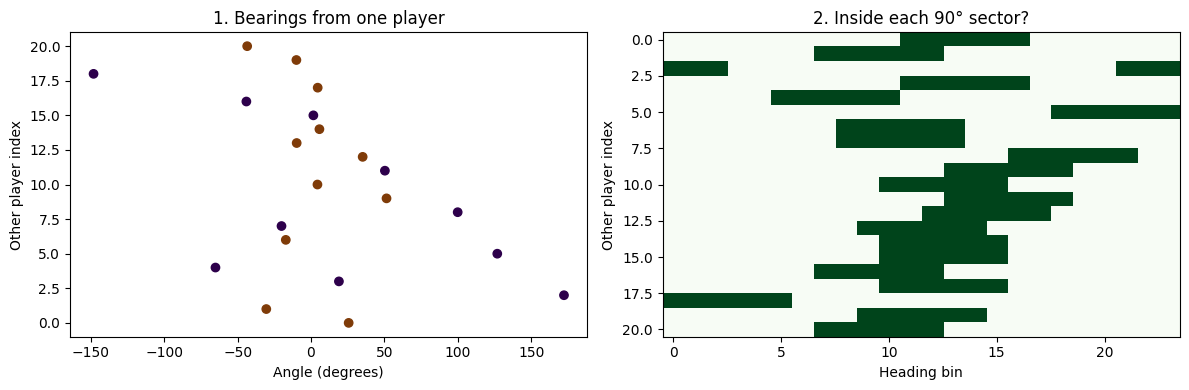

In [7]:
pid=snapshot[snapshot.team_id.eq(1802)].player_id.iloc[0]
bearings=relative_bearings(snapshot,pid,-1)
headings=np.linspace(-np.pi,np.pi,24,endpoint=False)
membership=np.abs(np.angle(np.exp(1j*(bearings.bearing.to_numpy()[:,None]-headings))))<=np.pi/4+1e-12
display(bearings[['player_id','same_team','bearing']].head())
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].scatter(np.degrees(bearings.bearing),np.arange(len(bearings)),c=bearings.same_team,cmap='PuOr')
axs[0].set(title='1. Bearings from one player',xlabel='Angle (degrees)',ylabel='Other player index')
axs[1].imshow(membership,aspect='auto',cmap='Greens')
axs[1].set(title='2. Inside each 90° sector?',xlabel='Heading bin',ylabel='Other player index')
plt.tight_layout()
plt.show()

## Supervised role classification from scratch
Pleuler used XGBoost. To expose the training calculation without adding an ML framework, this cell defines a multinomial linear classifier with softmax and gradient descent. A linear model is less flexible than XGBoost. Train it on **many reviewed matches**, splitting by match/player. We test its numerical mechanics on a labeled synthetic example only. No accuracy against noisy single-match metadata is presented as tactical-role performance.

#### Helper: `softmax`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [8]:
def softmax(z):
    z=z-z.max(axis=1,keepdims=True);p=np.exp(z);return p/p.sum(axis=1,keepdims=True)

#### Helper: `train_roles`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [9]:
def train_roles(X,y,n_classes,steps=600,lr=.1):
    X=np.c_[np.ones(len(X)),np.asarray(X,float)];W=np.zeros((X.shape[1],n_classes))
    target=np.eye(n_classes)[np.asarray(y,int)]
    for _ in range(steps):W-=lr*X.T@(softmax(X@W)-target)/len(X)
    return W

In [10]:
rng=np.random.default_rng(7)
toy_X=np.r_[rng.normal(-2,.3,(20,2)),rng.normal(2,.3,(20,2))]
toy_y=np.repeat([0,1],20)
W=train_roles(toy_X,toy_y,2)
assert (softmax(np.c_[np.ones(40),toy_X]@W).argmax(axis=1)==toy_y).all()
print('Synthetic optimizer check passed; real role-model training needs reviewed labels.')

Synthetic optimizer check passed; real role-model training needs reviewed labels.


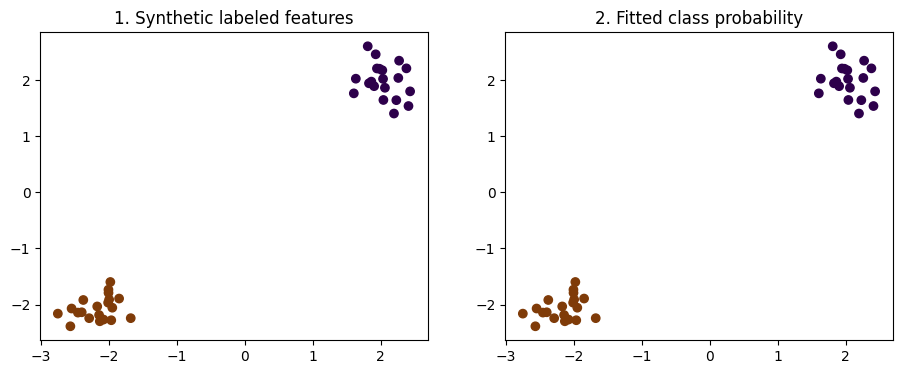

In [11]:
probability=softmax(np.c_[np.ones(len(toy_X)),toy_X]@W)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].scatter(toy_X[:,0],toy_X[:,1],c=toy_y,cmap='PuOr')
axs[0].set_title('1. Synthetic labeled features')
axs[1].scatter(toy_X[:,0],toy_X[:,1],c=probability[:,1],cmap='PuOr',vmin=0,vmax=1)
axs[1].set_title('2. Fitted class probability')
plt.show()

## Review the full method
Trace each final quantity back through its helper functions, intermediate arrays and visual diagnostics. Change one modeling assumption and rerun its dependent cells. Review coverage, attack direction, phase context and evaluation design before interpreting real sample results. Keep synthetic demonstrations and proxy quantities separate from trained or production model outputs.

This notebook is deliberately self-contained. Shared *concepts* such as smoothing or graph normalization are repeated inline where needed; another notebook never needs to run first.
